# 08 — Figure 2: decomposition of the Walker circulation response

All 23 events, fractional anomalies relative to the control run,
δX = (X − X̄) / X̄, for

* ω500,E−W (Methods Eq. 4; positive = stronger Walker circulation), and
* F_net,W−E (Methods Eq. 6; positive = stronger zonal energy-input contrast).

Both indices are defined so that positive means "stronger Walker circulation",
so a fractional anomaly has the same sign meaning on both axes.

* (a) FULL vs UNIFORM + PATTERN — additivity.
* (b) FULL vs PATTERN — pattern dominance.
* (c) FULL ω500 vs PATTERN F_net — energetic control. The dashed 1:1 line is
  what a change in energy input alone would give if the stability
  did not change.

Least-squares fits (solid). Slope ± 1 standard error and r² are not printed on
the panels (quote them in the text); the full statistics are written to
`figures/fig2_regression_stats.csv`.

Needs only the two tables in `data/` (from `04` and `05`), so it runs anywhere.
Output: `figures/fig2_three_panel_scatter.png` / `.pdf` (Figure 2) and
`figures/figS1_three_panel_scatter_uniform.png` / `.pdf` (Figure S1: the same
figure with the UNIFORM runs added to panel b). The per-event numbers are
tabulated in `12` (Table S1).

In [2]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

plt.rcParams.update({
    "font.size": 8, "font.family": "sans-serif",
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
FIG_WIDTH = 7.0   # inches, full page width in print

## Step 1 — one row per event, fractional anomalies

In [3]:
df = pd.read_csv(cfg.ANALYSIS_CSV_PATH)
df["Event"] = df["Event"].str.replace("\xa0", " ").str.strip()
clim = pd.read_csv(cfg.CLIMATOLOGY_CSV_PATH)

omega_clim = float(clim.loc[0, "eastminuswest_omega500"])   # Pa/s, > 0
fnet_clim = float(clim.loc[0, "westminuseast_F_net"])       # W/m2, > 0

omega = df.pivot(index="Year", columns="Run", values="eastminuswest_omega500")
fnet = df.pivot(index="Year", columns="Run", values="westminuseast_F_net")
info = df.drop_duplicates("Year").set_index("Year")[["Event", "Strength", "DJF"]]

events = info.copy()
events["d_full"] = (omega["Full Run"] - omega_clim) / omega_clim
events["d_uniform"] = (omega["Uniform Run"] - omega_clim) / omega_clim
events["d_pattern"] = (omega["Pattern Run"] - omega_clim) / omega_clim
events["d_fnet_pattern"] = (fnet["Pattern Run"] - fnet_clim) / fnet_clim
events["d_fnet_uniform"] = (fnet["Uniform Run"] - fnet_clim) / fnet_clim
events["sst_uniform"] = df.drop_duplicates("Year").set_index("Year")["sst_mean_input"]   # °C, the UNIFORM anomaly

assert events.notna().all().all(), "missing values -- run 04 and 05 for every event first"
print(f"{len(events)} events; control: omega_E-W = {omega_clim:.4f} Pa/s, F_net,W-E = {fnet_clim:.2f} W/m2")
events.round(3)

23 events; control: omega_E-W = 0.0680 Pa/s, F_net,W-E = 69.27 W/m2


,Event,Strength,DJF,d_full,d_uniform,d_pattern,d_fnet_pattern,d_fnet_uniform,sst_uniform
Year,,,,,,,,,
1983,El Niño,Very Strong,2.41,-0.760,0.026,-0.814,-0.844,0.055,0.247
1984,La Niña,Weak,-0.77,0.045,-0.008,0.023,0.131,-0.035,-0.135
1985,La Niña,Moderate,-1.27,0.133,0.005,0.118,0.262,-0.053,-0.318
1986,La Niña,Weak,-0.70,0.076,-0.005,0.081,0.243,-0.041,-0.224
1987,El Niño,Moderate,1.16,-0.274,-0.006,-0.260,-0.315,0.005,0.087
1988,El Niño,Weak,0.72,-0.136,0.002,-0.137,-0.254,0.019,0.231
1989,La Niña,Strong,-1.87,0.086,-0.018,0.096,0.432,-0.089,-0.337
1992,El Niño,Strong,1.75,-0.326,0.001,-0.343,-0.373,0.003,0.076
1995,El Niño,Weak,1.00,-0.148,0.005,-0.151,-0.079,0.002,0.071


## Step 2 — regressions

In [4]:
def regression(x, y):
    r = stats.linregress(x, y)
    t = stats.t.ppf(0.975, len(x) - 2)
    return dict(n=len(x), slope=r.slope, slope_se=r.stderr,
                slope_ci95_low=r.slope - t * r.stderr, slope_ci95_high=r.slope + t * r.stderr,
                intercept=r.intercept, r2=r.rvalue ** 2, p_value=r.pvalue)


PANELS = {
    "a": dict(x=events["d_uniform"] + events["d_pattern"],
              xlabel=r"$\delta\omega_{500,\mathrm{E-W}}$  (UNIFORM + PATTERN)"),
    "b": dict(x=events["d_pattern"],
              xlabel=r"$\delta\omega_{500,\mathrm{E-W}}$  (PATTERN)"),
    "c": dict(x=events["d_fnet_pattern"],
              xlabel=r"$\delta F_{\mathrm{net,W-E}}$  (PATTERN)"),
}
YLABEL = r"$\delta\omega_{500,\mathrm{E-W}}$  (FULL)"

results = {k: regression(p["x"], events["d_full"]) for k, p in PANELS.items()}
stats_table = pd.DataFrame(results).T
stats_table.index.name = "panel"
print(stats_table.round(4).to_string())

          n   slope  slope_se  slope_ci95_low  slope_ci95_high  intercept      r2  p_value
panel                                                                                     
a      23.0  1.0279    0.0169          0.9927           1.0631    -0.0010  0.9943      0.0
b      23.0  1.0017    0.0147          0.9712           1.0321     0.0025  0.9955      0.0
c      23.0  0.6721    0.0405          0.5879           0.7564    -0.0966  0.9292      0.0


## Step 3 — draw the figure

Colour = event type and strength (same palette as `01`). The figure is drawn
twice: Figure 2, and Figure S1 with the UNIFORM runs added to panel (b) as open
grey circles (x = δω500 of UNIFORM), which shows directly that UNIFORM stays near
zero (the result the main text cites as Figure S1).

legend classes with no event: La Niña – Very Strong -- just added in legend for asymmetry
saved figures/fig2_three_panel_scatter.png
saved figures/fig2_three_panel_scatter.pdf


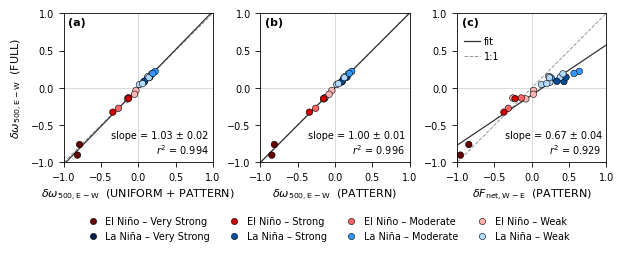

saved figures/figS1_three_panel_scatter_uniform.png
saved figures/figS1_three_panel_scatter_uniform.pdf


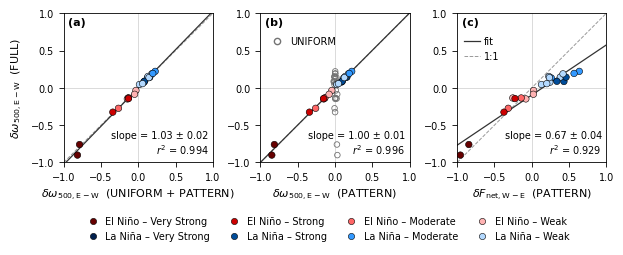

In [7]:
FIGURES = [(False, "fig2_three_panel_scatter"),            # Figure 2
           (True, "figS1_three_panel_scatter_uniform")]    # Figure S1: + UNIFORM runs in (b)
LEGEND_ALL_CATEGORIES = True   # list all 8 type × strength classes, including Very Strong La Niña (no such event in the catalog)

CATEGORY_COLOR = {
    "El Niño": {"Very Strong": "#660000", "Strong": "#CC0000", "Moderate": "#FF6666", "Weak": "#FFB3B3"},
    "La Niña": {"Very Strong": "#001F4D", "Strong": "#004C99", "Moderate": "#3399FF", "Weak": "#B3D9FF"},
}
colors = [CATEGORY_COLOR[e][s] for e, s in zip(events["Event"], events["Strength"])]
LIM = 1.0

for show_uniform, name in FIGURES:
    fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, 2.75), gridspec_kw={"wspace": 0.32})

    for ax, (panel, p) in zip(axes, PANELS.items()):
        x, y, res = p["x"], events["d_full"], results[panel]
        ax.axhline(0, color="0.8", linewidth=0.5, zorder=0)
        ax.axvline(0, color="0.8", linewidth=0.5, zorder=0)
        ax.plot([-LIM, LIM], [-LIM, LIM], linestyle="--", color="0.6", linewidth=0.7, zorder=1)
        xs = np.array([-LIM, LIM])
        ax.plot(xs, res["intercept"] + res["slope"] * xs, color="0.2", linewidth=0.9, zorder=2)
        if panel == "b" and show_uniform:
            ax.scatter(events["d_uniform"], y, facecolors="none", edgecolors="0.45", linewidth=0.6, s=16, zorder=3)
        ax.scatter(x, y, c=colors, edgecolor="black", linewidth=0.4, s=22, zorder=4)

        ax.set_xlim(-LIM, LIM)
        ax.set_ylim(-LIM, LIM)
        ax.set_aspect("equal")
        ax.set_xticks([-1, -0.5, 0, 0.5, 1])
        ax.set_yticks([-1, -0.5, 0, 0.5, 1])
        ax.set_xlabel(p["xlabel"], fontsize=8)
        if panel == "a":
            ax.set_ylabel(YLABEL, fontsize=8)
        ax.text(0.03, 0.97, f"({panel})", transform=ax.transAxes, fontsize=8, fontweight="bold", va="top", ha="left")
        # slope and r² on the panel (switched off; values are in figures/fig2_regression_stats.csv)
        ax.text(0.97, 0.04, f"slope = {res['slope']:.2f} ± {res['slope_se']:.2f}\n$r^2$ = {res['r2']:.3f}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=7)

    # legend: one row per event type; with LEGEND_ALL_CATEGORIES all 8 classes, otherwise only those that occur
    present = set(zip(events["Event"], events["Strength"]))
    missing = [f"{e} – {s}" for e in ["El Niño", "La Niña"] for s in ["Very Strong", "Strong", "Moderate", "Weak"]
               if (e, s) not in present]
    if missing and not show_uniform:
        print("legend classes with no event:", ", ".join(missing), "-- just added in legend for asymmetry" if LEGEND_ALL_CATEGORIES else "")
    blank = Line2D([], [], linestyle="", label=" ")
    legend_handles = []
    for strength in ["Very Strong", "Strong", "Moderate", "Weak"]:          # column-major: El Niño above La Niña
        for event in ["El Niño", "La Niña"]:
            if LEGEND_ALL_CATEGORIES or (event, strength) in present:
                legend_handles.append(Line2D([0], [0], marker="o", linestyle="", markersize=4.5,
                                             markerfacecolor=CATEGORY_COLOR[event][strength], markeredgecolor="black",
                                             markeredgewidth=0.4, label=f"{event} – {strength}"))
            else:
                legend_handles.append(blank)
    fig.legend(handles=legend_handles, loc="upper center", ncol=4, frameon=False, fontsize=7,
               bbox_to_anchor=(0.5, 0.06), columnspacing=1.5, handletextpad=0.3)

    line_handles = [Line2D([0], [0], color="0.2", linewidth=0.9, label="fit"),
                    Line2D([0], [0], color="0.6", linewidth=0.7, linestyle="--", label="1:1")]
    if show_uniform:
        uniform_handle = Line2D([0], [0], marker="o", linestyle="", markersize=4.5, markerfacecolor="none",
                                markeredgecolor="0.45", label="UNIFORM")
        axes[1].legend(handles=[uniform_handle], loc="upper left", bbox_to_anchor=(0.0, 0.89), frameon=False,
                       fontsize=7, handletextpad=0.3, borderaxespad=0.3)
    axes[2].legend(handles=line_handles, loc="upper left", bbox_to_anchor=(0.0, 0.89), frameon=False, fontsize=7,
                   handlelength=1.6, handletextpad=0.4, borderaxespad=0.3)

    os.makedirs(cfg.FIGURES_DIR, exist_ok=True)
    for ext in ["png", "pdf"]:
        out_path = os.path.join(cfg.FIGURES_DIR, f"{name}.{ext}")
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
        print("saved", os.path.relpath(out_path, cfg.REPO_ROOT))
    plt.show()

stats_table.to_csv(os.path.join(cfg.FIGURES_DIR, "fig2_regression_stats.csv"), float_format="%.6g")

## Step 4 — numbers quoted in the text

* the UNIFORM Walker response, which the text describes as "almost zero" (Figure S1);
* the control-run offset (README, Definitions): the UNIFORM runs regressed on
  their tropical-mean SST anomaly and evaluated at zero anomaly. A run with zero SST
  anomaly would reproduce the control exactly if both baselines were identical, so
  the intercept measures how far the perpetual-SST runs sit from the observed-SST control.

In [6]:
print("FULL     δω500: min {:+.3f}, max {:+.3f}, std {:.3f}".format(events.d_full.min(), events.d_full.max(), events.d_full.std()))
print("UNIFORM  δω500: min {:+.3f}, max {:+.3f}, std {:.3f}".format(events.d_uniform.min(), events.d_uniform.max(), events.d_uniform.std()))
print("FULL - (UNIFORM + PATTERN): max |residual| = {:.3f}".format((events.d_full - events.d_uniform - events.d_pattern).abs().max()))

for label, column in [("δω500,E-W", "d_uniform"), ("δF_net,W-E", "d_fnet_uniform")]:
    fit = stats.linregress(events["sst_uniform"], events[column])
    print(f"control offset, UNIFORM {label} at zero SST anomaly: {fit.intercept:+.4f} ± {fit.intercept_stderr:.4f}")

FULL     δω500: min -0.902, max +0.221, std 0.289
UNIFORM  δω500: min -0.018, max +0.032, std 0.013
FULL - (UNIFORM + PATTERN): max |residual| = 0.086
control offset, UNIFORM δω500,E-W at zero SST anomaly: +0.0045 ± 0.0020
control offset, UNIFORM δF_net,W-E at zero SST anomaly: -0.0054 ± 0.0025
